# Л1 — Підготовка даних

Велика частина роботи в Data Science — збір і підготовка даних. Саме тут виникає багато неочікуваних проблем і пасток.

Ноутбук нижче базово показує, як працювати з даними й готувати їх. Він не охоплює всіх можливих сценаріїв, а приклади в ньому часом сильно спрощені. Проте він дасть розуміння, де шукати помилки і як з ними боротися. Більше туторіалів — у [Kaggle Learn](https://www.kaggle.com/learn), зокрема [Data Cleaning](https://www.kaggle.com/learn/data-cleaning).

Базовий алгоритм підготовки даних може виглядати так (у дужках — кроки цього ноутбука):

- зчитування даних і початкове дослідження (1);
- дослідження структури й особливостей даних, зміна типів (2);
- об'єднання даних з різних джерел (3–4);
- робота з пропущеними й зламаними значеннями: drop, fill тощо (5, 7, 8);
- пошук outliers: drop, clip тощо (6);
- пошук зайвих і бракуючих колонок (9).

І головне: з кожною дією треба бути обережним. Outliers можуть бути реальними даними, які логічно пояснюються і які не можна видаляти. А пропущені значення можуть щось означати й бути корисними. Обидва випадки є в цій роботі.

Далі бувають кроки, специфічні для певних моделей чи алгоритмів:

- scaling: normalization, standardization тощо;
- обробка категорійних колонок: one-hot encoding тощо;
- dimensionality reduction.

Тут вони не розглядаються, частину з них побачите в Л2 і Л3.

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Опис даних і таблиця недоліків — у `README.md`.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

## 1. Завантаження даних

На цьому етапі важливо впевнитися, що файли завантажено правильно, і подивитися, що взагалі всередині. Можуть допомогти `df.head()`, `df.tail()`, `df.shape` і `df.dtypes`.

Що ви маєте зрозуміти?

- Чи зчиталися дані взагалі?
- Чи правильно розпарсилися рядки, колонки й значення?
- Які типи в колонок?
- Які приблизно значення?
- Скільки рядків і колонок?

In [4]:
df_meters = pd.read_parquet(f"../variants/{8}/meters.parquet")
df_registry = pd.read_csv(f"../variants/{8}/registry.csv")

print("Розмір df_meters (рядки, колонки):", df_meters.shape)
print("Розмір df_registry (рядки, колонки):", df_registry.shape)

print("\nТипи даних у df_meters:\n", df_meters.dtypes)

Розмір df_meters (рядки, колонки): (525556, 4)
Розмір df_registry (рядки, колонки): (800, 7)

Типи даних у df_meters:
 meter_id                      str
ts                 datetime64[us]
consumption_kwh           float64
record_ts          datetime64[us]
dtype: object


## 2. Звірка з описом

Іноді бізнес надає опис ідеальних даних, але реальні дані часто з ним не збігаються. Тому спершу подивіться, чи ваші дані відповідають опису в `README.md`. Може допомогти `df.describe()`.

Перевірте (але поки не виправляйте):

- типи колонок: якщо число прочиталося як текст, частина операцій спрацює неправильно;
- скільки рядків мають `customer_type`, `tariff` чи `electric_heating`, яких немає в описі;
- скільки рядків мають `ts`, `connection_year` чи `years_connected` поза межами з опису;
- скільки різних лічильників у кожному файлі — мають бути по 800.

Можуть допомогти `isin`, `between` і `nunique`.

Недоліки з таблиці в `README.md` перевірятимете далі, кожен у своєму кроці. Межі споживання залежать від типу абонента, а тип є лише в реєстрі, тому їх перевірите після об'єднання, на кроці 6.

In [5]:
meters_unique = df_meters["meter_id"].nunique()
registry_unique = df_registry["meter_id"].nunique()
print(f"Унікальних лічильників у meters: {meters_unique} (очікується 800)")
print(f"Унікальних лічильників у registry: {registry_unique} (очікується 800)")

valid_customer_types = ["household", "small_business", "industrial"]
valid_tariffs = ["single", "dual_zone"]
valid_heating = [0, 1]

invalid_cust = (~df_registry["customer_type"].isin(valid_customer_types)).sum()
invalid_tariff = (~df_registry["tariff"].isin(valid_tariffs)).sum()
invalid_heating = (~df_registry["electric_heating"].isin(valid_heating)).sum()

print(f"\nРядків з невідомим customer_type: {invalid_cust}")
print(f"Рядків з невідомим tariff: {invalid_tariff}")
print(f"Рядків з невідомим electric_heating: {invalid_heating}")

invalid_conn_year = (~df_registry["connection_year"].between(1985, 2024)).sum()
invalid_years_conn = (~df_registry["years_connected"].between(1, 41)).sum()

print(f"\nРядків з connection_year поза [1985, 2024]: {invalid_conn_year}")
print(f"Рядків з years_connected поза [1, 41]: {invalid_years_conn}")

min_ts = pd.Timestamp("2026-01-05 00:00")
max_ts = pd.Timestamp("2026-02-01 23:00")
invalid_ts = (~df_meters["ts"].between(min_ts, max_ts)).sum()

print(f"\nРядків з ts поза межами періоду: {invalid_ts}")

Унікальних лічильників у meters: 800 (очікується 800)
Унікальних лічильників у registry: 800 (очікується 800)

Рядків з невідомим customer_type: 0
Рядків з невідомим tariff: 0
Рядків з невідомим electric_heating: 0

Рядків з connection_year поза [1985, 2024]: 0
Рядків з years_connected поза [1, 41]: 0

Рядків з ts поза межами періоду: 0


## 3. Реєстр: номери й райони (D-E, D-F)

Дані зберігаються в різних системах, тому формат ідентифікатора може не збігатися: `" UA123456"` для pandas — інший номер, ніж `UA123456`. Наївний join призведе до того, що частина даних втратиться. Так само `podil` і `Podil` — різні райони, і будь-який підрахунок по районах буде хибним.

Для D-E і D-F виведіть, скільки рядків реєстру зіпсовано, і виправте їх так, як сказано в таблиці недоліків. Можуть допомогти `str.fullmatch(r"UA\d{6}")`, `isin`, `str.strip()`, `str.lstrip("0")` і `str.capitalize()`.

In [6]:
valid_meter_pattern = r"^UA\d{6}$"
broken_meters_mask = ~df_registry["meter_id"].str.fullmatch(valid_meter_pattern)
broken_meters_count = broken_meters_mask.sum()
print(f"D-E: Зіпсованих номерів у реєстрі: {broken_meters_count}")

df_registry["meter_id"] = (
    df_registry["meter_id"]
    .astype(str)
    .str.strip()
    .str.lstrip("0")
)

remaining_broken_meters = (~df_registry["meter_id"].str.fullmatch(valid_meter_pattern)).sum()
print(f"D-E: Залишилося зіпсованих номерів: {remaining_broken_meters}")


valid_districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
broken_districts_mask = ~df_registry["district"].isin(valid_districts)
broken_districts_count = broken_districts_mask.sum()
print(f"\nD-F: Рядків із некоректним district: {broken_districts_count}")

df_registry["district"] = (
    df_registry["district"]
    .astype(str)
    .str.strip()
    .str.capitalize()
)

remaining_broken_districts = (~df_registry["district"].isin(valid_districts)).sum()
print(f"D-F: Залишилося некоректних районів: {remaining_broken_districts}")

D-E: Зіпсованих номерів у реєстрі: 96
D-E: Залишилося зіпсованих номерів: 0

D-F: Рядків із некоректним district: 80
D-F: Залишилося некоректних районів: 0


## 4. Об'єднання

Тепер погодинні дані можна об'єднати з реєстром за `meter_id` (join, у pandas — `merge`). pandas не попереджає, коли рядок не знайшов пари, тому якість об'єднання треба перевірити самому.

Об'єднану таблицю назвіть `df`, з нею працюватимете далі. Перевірте й виведіть:

- кількість рядків до і після об'єднання — вона не має змінитися;
- кількість рядків без атрибутів абонента (пропуск у `customer_type`) — має бути 0.

Може допомогти `merge(..., how="left", validate="m:1")`: `validate` ще й перевірить, що кожному лічильнику відповідає один рядок реєстру.

In [7]:
rows_before = len(df_meters)

df = df_meters.merge(df_registry, on="meter_id", how="left", validate="m:1")

rows_after = len(df)
missing_attrs = df["customer_type"].isna().sum()

print(f"Кількість рядків до об'єднання: {rows_before}")
print(f"Кількість рядків після об'єднання: {rows_after}")
print(f"Рядків без атрибутів абонента (пропусків у customer_type): {missing_attrs}")

Кількість рядків до об'єднання: 525556
Кількість рядків після об'єднання: 525556
Рядків без атрибутів абонента (пропусків у customer_type): 0


## 5. Повторні відправки (D-C)

Повторна відправка — та сама година того самого лічильника ще раз, іноді з уточненим значенням. Якщо лишити обидва записи, споживання за цю годину подвоїться. Лишаємо найпізніший за `record_ts` запис як найсвіжіший.

Виведіть кількість рядків і кількість різних пар `meter_id` і `ts`, потім зніміть повтори. Можуть допомогти `duplicated(["meter_id", "ts"])`, `sort_values("record_ts")` і `drop_duplicates(["meter_id", "ts"], keep="last")`.

In [8]:
total_rows = len(df)
unique_pairs = len(df.drop_duplicates(subset=["meter_id", "ts"]))
duplicates_count = total_rows - unique_pairs

print(f"D-C: Усього рядків: {total_rows}")
print(f"D-C: Унікальних пар (meter_id, ts): {unique_pairs}")
print(f"D-C: Кількість повторних відправок (дублікатів): {duplicates_count}")

df = df.sort_values("record_ts").drop_duplicates(subset=["meter_id", "ts"], keep="last")

print(f"Рядків після видалення повторів: {len(df)}")

D-C: Усього рядків: 525556
D-C: Унікальних пар (meter_id, ts): 515359
D-C: Кількість повторних відправок (дублікатів): 10197
Рядків після видалення повторів: 515359


## 6. Одиниці виміру (D-D)

Значення у Вт·год схожі на викиди, але це не шум, а помилка одиниць. Якщо їх видалити, зникнуть цілі абоненти.

1. Для кожного лічильника порахуйте відношення його медіани `consumption_kwh` до медіани всіх рядків його `customer_type`. Більше 100 — лічильник звітує у Вт·год.
2. Побудуйте графік медіан лічильників за `customer_type` з логарифмічною віссю, наприклад boxplot.
3. Виведіть кількість лічильників у Вт·год, найбільше відношення серед решти лічильників і найменше серед лічильників у Вт·год (якщо таких немає — лише найбільше відношення серед усіх). Ці числа — доказ у звіті: вони показують, наскільки далеко від порога обидві групи.
4. Поділіть значення цих лічильників на 1000 і виведіть, скільки рядків поза межами споживання з опису, — має бути 0.

Можуть допомогти `DataFrame.boxplot(column=..., by="customer_type")`, `plt.yscale("log")` і `between`. Клітинку з діленням не запускайте двічі: значення поділяться ще раз. Якщо так сталося, перезапустіть ноутбук з початку.

<Figure size 800x500 with 0 Axes>

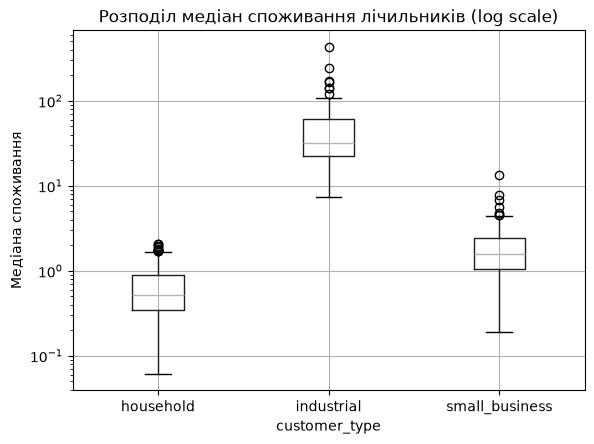

D-D: Лічильників у Вт·год: 0
Найбільше відношення серед усіх лічильників: 12.19
Рядків поза межами споживання після виправлення: 0


In [9]:
meter_median = df.groupby("meter_id")["consumption_kwh"].median()
meter_type = df.groupby("meter_id")["customer_type"].first()
type_median = df.groupby("customer_type")["consumption_kwh"].median()

ratio = meter_median / meter_type.map(type_median)

plt.figure(figsize=(8, 5))
df_plot = pd.DataFrame({"meter_median": meter_median, "customer_type": meter_type})
df_plot.boxplot(column="meter_median", by="customer_type")
plt.yscale("log")
plt.title("Розподіл медіан споживання лічильників (log scale)")
plt.suptitle("")
plt.ylabel("Медіана споживання")
plt.show()

wh_mask = ratio > 100
wh_meters = ratio[wh_mask].index.tolist()
wh_count = len(wh_meters)

max_normal_ratio = ratio[~wh_mask].max()
if wh_count > 0:
    min_wh_ratio = ratio[wh_mask].min()
    print(f"D-D: Лічильників у Вт·год: {wh_count}")
    print(f"Найбільше відношення серед звичайних: {max_normal_ratio:.2f}")
    print(f"Найменше відношення серед Вт·год: {min_wh_ratio:.2f}")
else:
    print(f"D-D: Лічильників у Вт·год: 0")
    print(f"Найбільше відношення серед усіх лічильників: {max_normal_ratio:.2f}")

if wh_count > 0:
    df.loc[df["meter_id"].isin(wh_meters), "consumption_kwh"] /= 1000

min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1.0}
max_kwh = {"household": 10.0, "small_business": 60.0, "industrial": 1200.0}

out_of_bounds = (~df["consumption_kwh"].between(
    df["customer_type"].map(min_kwh),
    df["customer_type"].map(max_kwh)
)).sum()

print(f"Рядків поза межами споживання після виправлення: {out_of_bounds}")

## 7. Лічильники, що замовкли (D-A)

Пропуски не заповнюємо: те, що лічильник замовк, уже є інформацією про можливу відмову, а середнє її стерло б. Не видаляємо теж: до відмови лічильник передавав правильні дані.

Для кожного лічильника порахуйте, скільки годин минуло від його останнього `ts` до `2026-02-01 23:00`; більше 48 — замовк. Як на кроці 6, виведіть кількість замовклих, найбільшу тишу серед решти й найменшу серед замовклих (якщо замовклих немає — лише найбільшу тишу серед усіх).

Номери замовклих лічильників збережіть списком `silent`, наприклад `list(....index)`: він знадобиться в регресії.

Можуть допомогти `pd.Timestamp("2026-02-01 23:00")` і `/ pd.Timedelta(hours=1)`.

In [10]:
target_ts = pd.Timestamp("2026-02-01 23:00")

last_ts = df.groupby("meter_id")["ts"].max()

silence_hours = (target_ts - last_ts) / pd.Timedelta(hours=1)

silent_mask = silence_hours > 48
silent = silence_hours[silent_mask].index.tolist()
silent_count = len(silent)

print(f"D-A: Кількість лічильників, що замовкли: {silent_count}")

max_normal_silence = silence_hours[~silent_mask].max() if (~silent_mask).any() else 0
if silent_count > 0:
    min_silent_silence = silence_hours[silent_mask].min()
    print(f"Найбільша тиша серед решти лічильників: {max_normal_silence:.1f} год")
    print(f"Найменша тиша серед замовклих: {min_silent_silence:.1f} год (поріг: 48 год)")
else:
    print(f"Найбільша тиша серед усіх лічильників: {max_normal_silence:.1f} год (поріг: 48 год)")

D-A: Кількість лічильників, що замовкли: 48
Найбільша тиша серед решти лічильників: 1.0 год
Найменша тиша серед замовклих: 148.0 год (поріг: 48 год)


## 8. Завмерлі лічильники (D-B)

Завмерлі значення виглядають правдоподібно, і ні середнє, ні максимум їх не видають. Помітно лише те, що значення перестали змінюватися. Такі лічильники не видаляємо: частина їхніх годин справна.

Для кожного лічильника порахуйте частку різних значень `consumption_kwh` серед його записів; менше 0.65 — завмер. Побудуйте гістограму цієї частки по лічильниках. Як на кроці 6, виведіть кількість завмерлих, найменшу частку серед решти й найбільшу серед завмерлих (якщо завмерлих немає — лише найменшу частку серед усіх).

Номери завмерлих лічильників збережіть списком `frozen`: він знадобиться в регресії.

Можуть допомогти `nunique()`, `size()` і `plt.hist`.

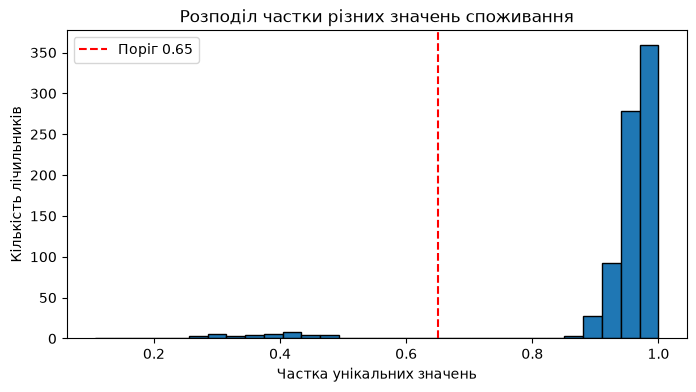

D-B: Кількість завмерлих лічильників: 40
Найменша частка серед решти лічильників: 0.866
Найбільша частка серед завмерлих: 0.488 (поріг: 0.65)


In [11]:
unique_counts = df.groupby("meter_id")["consumption_kwh"].nunique()
total_counts = df.groupby("meter_id")["consumption_kwh"].size()

diversity_ratio = unique_counts / total_counts

plt.figure(figsize=(8, 4))
plt.hist(diversity_ratio, bins=30, edgecolor="black")
plt.axvline(0.65, color="red", linestyle="--", label="Поріг 0.65")
plt.title("Розподіл частки різних значень споживання")
plt.xlabel("Частка унікальних значень")
plt.ylabel("Кількість лічильників")
plt.legend()
plt.show()

frozen_mask = diversity_ratio < 0.65
frozen = diversity_ratio[frozen_mask].index.tolist()
frozen_count = len(frozen)

print(f"D-B: Кількість завмерлих лічильників: {frozen_count}")

min_normal_ratio = diversity_ratio[~frozen_mask].min() if (~frozen_mask).any() else 0
if frozen_count > 0:
    max_frozen_ratio = diversity_ratio[frozen_mask].max()
    print(f"Найменша частка серед решти лічильників: {min_normal_ratio:.3f}")
    print(f"Найбільша частка серед завмерлих: {max_frozen_ratio:.3f} (поріг: 0.65)")
else:
    print(f"Найменша частка серед усіх лічильників: {min_normal_ratio:.3f} (поріг: 0.65)")

## 9. Кореляції

Колонка, що майже копіює іншу, не додає інформації: у кластеризації вона подвоює вагу того самого фактора, а в регресії робить коефіцієнти нестабільними. Технічна колонка `record_ts` після кроку 5 теж не потрібна.

Порахуйте кореляції між числовими колонками об'єднаної таблиці. Пару з кореляцією за модулем понад 0.95 вважайте копією і лиште з неї одну колонку. Приберіть `record_ts`. Підсумкову таблицю назвіть `result`.

Можуть допомогти `select_dtypes("number").corr().abs()` і `drop(columns=...)`.

In [12]:
numeric_cols = df.select_dtypes(include="number")
corr_matrix = numeric_cols.corr().abs()

high_corr_pairs = [
    (col1, col2, corr_matrix.loc[col1, col2])
    for col1 in corr_matrix.columns
    for col2 in corr_matrix.columns
    if col1 < col2 and corr_matrix.loc[col1, col2] > 0.95
]

print("Знайдені пари колонок-копій (кореляція > 0.95):")
for c1, c2, val in high_corr_pairs:
    print(f"- {c1} та {c2}: кореляція = {val:.4f}")

cols_to_drop = ["years_connected", "record_ts"]
result = df.drop(columns=cols_to_drop)

print(f"\nКолонки до видалення: {cols_to_drop}")
print(f"Розмір фінальної таблиці result: {result.shape}")

Знайдені пари колонок-копій (кореляція > 0.95):
- connection_year та years_connected: кореляція = 0.9990

Колонки до видалення: ['years_connected', 'record_ts']
Розмір фінальної таблиці result: (515359, 8)


## 10. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [13]:
districts = ["Podil", "Solomianka", "Darnytsia", "Obolon", "Sviatoshyn"]
min_kwh = {"household": 0.01, "small_business": 0.02, "industrial": 1}
max_kwh = {"household": 10, "small_business": 60, "industrial": 1200}
corr = result.select_dtypes("number").corr().abs()
copies = [(a, b) for a in corr for b in corr if a < b and corr.loc[a, b] > 0.95]

assert not result.duplicated(["meter_id", "ts"]).any(), "лишилися повтори лічильник–година"
assert result["meter_id"].nunique() == 800, "лічильників має бути 800"
assert result["meter_id"].str.fullmatch(r"UA\d{6}").all(), "є номери не у форматі UA і 6 цифр"
assert result["customer_type"].notna().all(), "є рядки без атрибутів абонента"
assert result["district"].isin(districts).all(), "є райони, яких немає в описі"
assert result["consumption_kwh"].between(result["customer_type"].map(min_kwh), result["customer_type"].map(max_kwh)).all(), "є споживання поза межами з опису"
assert not copies, f"лишилися колонки-копії: {copies}"
assert "record_ts" not in result, "технічна колонка record_ts лишилася"

result.to_parquet("cleaned.parquet", index=False)
print("усе гаразд:", result.shape)

усе гаразд: (515359, 8)


## 11. Регресія

Регресію часто використовують, щоб передбачати певні показники. Проте лінійна регресія також показує, як кожен показник впливає на результат. Це і є регресійний аналіз.

Для прикладу подивимося, як на добове споживання домогосподарства впливають електроопалення і двозонний тариф: `y = a + b₁·x₁ + b₂·x₂`.

- `y` — середнє споживання лічильника за добу, кВт·год;
- `x₁` — `electric_heating`, `x₂` — двозонний тариф (обидва 0 або 1);
- `b₁` і `b₂` — на скільки кВт·год на добу більше споживає абонент із цим фактором за однакового іншого;
- `a` — споживання без опалення на звичайному тарифі;
- R² — яку частку розкиду споживання пояснюють обидва фактори, від 0 до 1.

Регресія тут краща за просте порівняння середніх: двозонний тариф здебільшого мають будинки з опаленням, і різниця середніх за тарифом приписала б тарифу ще й споживання на опалення.

Нормалізація не потрібна: обидва фактори мають однаковий масштаб (0 або 1), тож `b₁` і `b₂` можна порівнювати напряму, а `y` лишається в кВт·год на добу, і коефіцієнти легко пояснити. Якби фактори мали різні одиниці, наприклад площу і рік, для порівняння впливу їх спершу стандартизували б.

Лічильники з `silent` і `frozen` не беремо: у `cleaned.parquet` вони лишаються, але їхнє середнє споживання спотворене.

Код майже готовий: допишіть `homes` і запустіть.

In [14]:
homes = result[
    (result["customer_type"] == "household") & 
    (~result["meter_id"].isin(silent + frozen))
]

per_meter = homes.groupby("meter_id").agg(
    kwh_per_day=("consumption_kwh", "mean"),
    electric_heating=("electric_heating", "first"),
    tariff=("tariff", "first"),
)
per_meter["kwh_per_day"] *= 24
per_meter["dual_zone"] = (per_meter["tariff"] == "dual_zone").astype(int)

x, y = per_meter[["electric_heating", "dual_zone"]], per_meter["kwh_per_day"]
model = LinearRegression().fit(x, y)
print("лічильників:", len(per_meter))
print(f"a = {model.intercept_:.2f}, b₁ (опалення) = {model.coef_[0]:.2f}, b₂ (двозонний тариф) = {model.coef_[1]:.2f}, R² = {model.score(x, y):.3f}")

лічильників: 467
a = 11.10, b₁ (опалення) = 16.28, b₂ (двозонний тариф) = 2.30, R² = 0.652
